# Temporal point processes: the event-time problem

A **temporal point process (TPP)** models a random set of event times

\[
0<t_1<t_2<\cdots<t_N.
\]

The central object is the **conditional intensity**

\[
\lambda(t\mid\mathcal H_t),
\]

where \(\mathcal H_t\) is everything observed before time \(t\). Informally, \(\lambda(t\mid\mathcal H_t)dt\) is the conditional probability of an event in a very small interval \([t,t+dt)\).

For one observed window \([0,C]\), the log-likelihood is

\[
\log p(\{t_i\})
=\sum_i \log\lambda(t_i\mid\mathcal H_{t_i})
-\int_0^C \lambda(s\mid\mathcal H_s)\,ds.
\]

The second term is what tells the model about **time with no events**, including the right-censored tail after the last event.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
from lifetime_clinical.tutorials.textbook import simulate_poisson, simulate_hawkes, hawkes_intensity

def next_wait_survival(grid, events, mu, alpha=0.0, beta=1.0):
    """Conditional next-event survival, restarted at each observed event."""
    values = np.empty_like(grid, dtype=float)
    for j, time in enumerate(grid):
        past = events[events <= time]
        origin = past[-1] if len(past) else 0.0
        elapsed = time - origin
        excitation = np.sum(alpha * np.exp(-beta * (origin - past)))
        cumulative_hazard = mu * elapsed + excitation * (-np.expm1(-beta * elapsed)) / beta
        values[j] = np.exp(-cumulative_hazard)
    return values


## Textbook model 1: homogeneous Poisson process

The simplest TPP assumes a constant intensity

\[
\lambda(t)=\lambda.
\]

Then the inter-arrival times \(\tau_i=t_i-t_{i-1}\) are independent

\[
\tau_i\sim\operatorname{Exponential}(\lambda),
\qquad
p(\tau)=\lambda e^{-\lambda\tau}.
\]

This is a useful baseline precisely because it says that the future does **not** depend on the past.

**Reading the plots.** Red crosses mark event times at \(y=0\) on intensity plots and \(y=1\) on survival plots; their height is a plotting convention. Each survival segment conditions on the latest event and on no subsequent event yet. At the next event we start a **new** waiting-time distribution at survival 1. The resulting sequence of segments is not a single survival function over the whole timeline. The final segment ends at the observation horizon without adding an event there.

**Fitting one patient.** For \(N\) observed events over an observation duration \(C\), maximise \(\ell(\lambda)=N\log\lambda-\lambda C\). The maximum-likelihood rate is \(\widehat\lambda=N/C\): events divided by total observed time, including the censored tail. A patient with no events has estimate zero. Do not estimate the rate using only the completed IATs and discard event-free follow-up. The examples here are simulations with specified parameters, not fitted models.


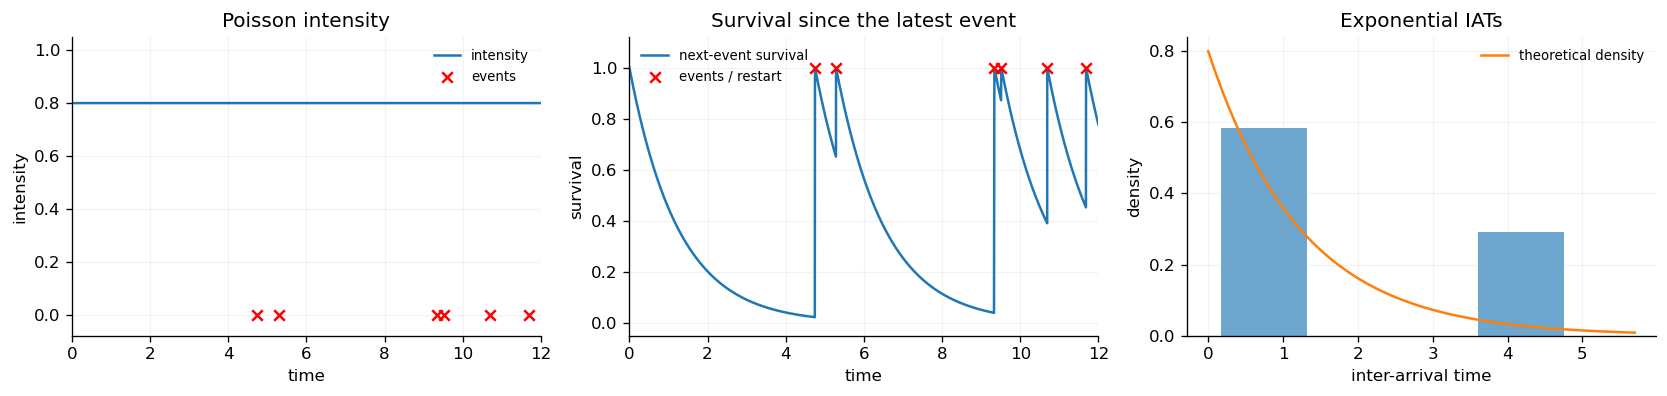

In [2]:
poisson_rate, horizon = .8, 12.0
poisson_events = simulate_poisson(rate=poisson_rate, horizon=horizon, seed=4)
iat = np.diff(np.r_[0, poisson_events])
grid = np.unique(np.r_[np.linspace(0, horizon, 1200), poisson_events])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].plot(grid, np.full_like(grid, poisson_rate), label="intensity")
axes[0].scatter(poisson_events, np.zeros_like(poisson_events), color="red", marker="x", s=40, label="events", zorder=3)
axes[0].set(xlim=(0, horizon), ylim=(-.08, 1.05), xlabel="time", ylabel="intensity", title="Poisson intensity")
axes[1].plot(grid, next_wait_survival(grid, poisson_events, poisson_rate), label="next-event survival")
axes[1].scatter(poisson_events, np.ones_like(poisson_events), color="red", marker="x", s=40, label="events / restart", zorder=3)
axes[1].set(xlim=(0, horizon), ylim=(-.05, 1.12), xlabel="time", ylabel="survival", title="Survival since the latest event")
axes[2].hist(iat, bins=8, density=True, alpha=.65)
x = np.linspace(0, max(iat) * 1.2, 200)
axes[2].plot(x, poisson_rate * np.exp(-poisson_rate * x), label="theoretical density")
axes[2].set(xlabel="inter-arrival time", ylabel="density", title="Exponential IATs")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=.15)
fig.tight_layout()
plt.show()


## Textbook model 2: Hawkes process

A Hawkes process introduces event-to-event dependence. With an exponential kernel,

\[
\lambda(t)=\mu+\sum_{t_i<t}\alpha e^{-\beta(t-t_i)}.
\]

Each event transiently changes the future intensity. This is appropriate when an event may make another event more likely soon afterwards. It is **not** a universal law for clinical events; it is an inductive bias.

**Fitting one patient.** Given that patient's event times in \([0,C]\), numerically maximise

\[
\ell(\mu,\alpha,\beta)=
\sum_i\log\left(\mu+\sum_{j<i}\alpha e^{-\beta(t_i-t_j)}\right)
-\mu C-\frac{\alpha}{\beta}\sum_i\left[1-e^{-\beta(C-t_i)}\right].
\]

This expression assumes an empty history at time zero. Optimisation constrains \(\mu>0\), \(\alpha\geq0\) and \(\beta>0\); imposing \(\alpha/\beta<1\) gives the stable stationary textbook model. The integral includes follow-up after the last event. A short patient timeline may not identify all three parameters well, so regularisation or fixing the decay scale can help. For cohort entry with unknown pre-study events, the empty-history assumption needs justification or a model of the initial excitation. We describe fitting here without implementing an optimiser.


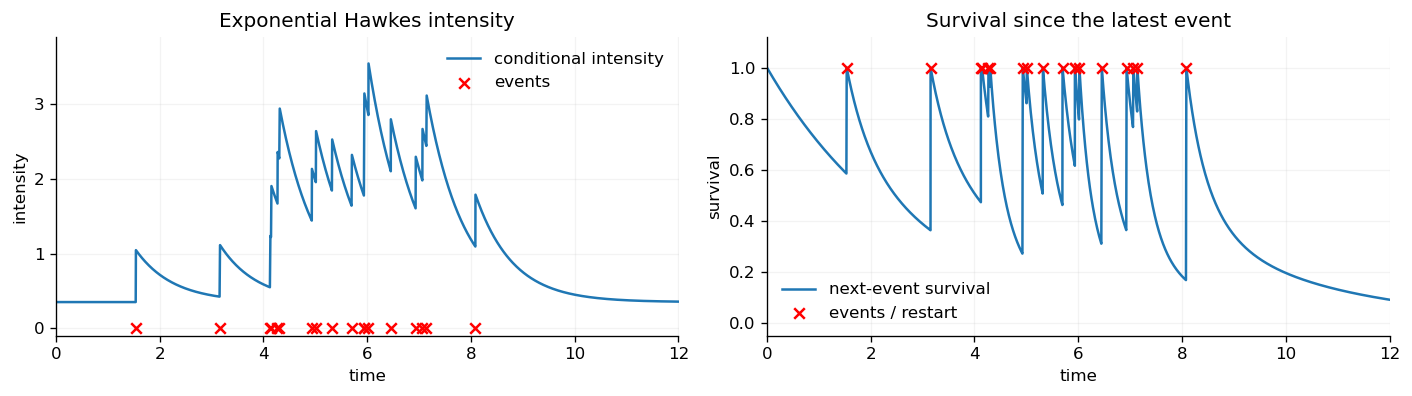

In [3]:
mu, alpha, beta, horizon = .35, .7, 1.4, 12.0
hawkes_events = simulate_hawkes(mu=mu, alpha=alpha, beta=beta, horizon=horizon, seed=8)
grid = np.unique(np.r_[np.linspace(0, horizon, 1200), hawkes_events])
lam = hawkes_intensity(grid, hawkes_events, mu, alpha, beta)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(grid, lam, label="conditional intensity")
axes[0].scatter(hawkes_events, np.zeros_like(hawkes_events), color="red", marker="x", s=40, label="events", zorder=3)
axes[0].set(xlabel="time", ylabel="intensity", ylim=(-.1, max(lam)*1.1), title="Exponential Hawkes intensity")
axes[1].plot(grid, next_wait_survival(grid, hawkes_events, mu, alpha, beta), label="next-event survival")
axes[1].scatter(hawkes_events, np.ones_like(hawkes_events), color="red", marker="x", s=40, label="events / restart", zorder=3)
axes[1].set(xlabel="time", ylabel="survival", ylim=(-.05, 1.12), title="Survival since the latest event")
for ax in axes:
    ax.set(xlim=(0, horizon))
    ax.legend(frameon=False)
    ax.grid(alpha=.15)
fig.tight_layout()
plt.show()


## Marked TPPs: when an event happens and what it is

An unmarked process records only event times. A **marked TPP** records pairs \((t_i,m_i)\), where the mark \(m_i\) describes the event. For a clinical timeline, it could be an outpatient, emergency or inpatient visit. The history now includes both past times and past marks.

For discrete event types, define one conditional intensity per type:

\[
\lambda_k(t\mid\mathcal H_t)dt
\approx P(\text{an event of type }k\text{ in }[t,t+dt)\mid\mathcal H_t).
\]

The total event intensity and the conditional type probabilities are

\[
\lambda(t\mid\mathcal H_t)=\sum_k\lambda_k(t\mid\mathcal H_t),
\qquad
P(m=k\mid\text{an event at }t,\mathcal H_t)
=\frac{\lambda_k(t\mid\mathcal H_t)}{\lambda(t\mid\mathcal H_t)},
\]

where the ratio is defined when the total intensity is positive. Thus the model answers two linked questions: **how soon is the next visit, and which type of visit will it be?** The type probabilities may depend on the waiting time; timing and type need not be independent.

A multivariate Hawkes model is one example:

\[
\lambda_k(t)=\mu_k+\sum_{t_i<t}\alpha_{k,m_i}e^{-\beta_{k,m_i}(t-t_i)}.
\]

Here \(\alpha_{k,j}\) describes how a past event of type \(j\) increases the future intensity of type \(k\). With nonnegative excitation coefficients, this permits both self-excitation and excitation across types. For example, an emergency visit could temporarily increase the intensity of an inpatient visit. This is a modelling assumption, not evidence of a causal clinical effect.

For an observation window \([0,C]\), the marked log-likelihood is

\[
\sum_i\log\lambda_{m_i}(t_i\mid\mathcal H_{t_i})
-\int_0^C\sum_k\lambda_k(s\mid\mathcal H_s)\,ds.
\]

Each observed event uses its type-specific intensity, while every event-free interval uses the total intensity: no event means no event of **any** type.


The illustration below uses a simple special case: assign independent event-type marks to the simulated Hawkes events with probabilities \(p_k\), so \(\lambda_k(t)=p_k\lambda(t)\). Colours and symbols identify event types at \(y=0\) on intensity and \(y=1\) on survival. The survival curve uses the total intensity of all types. This example does not include type-dependent excitation; the multivariate construction above can do so.


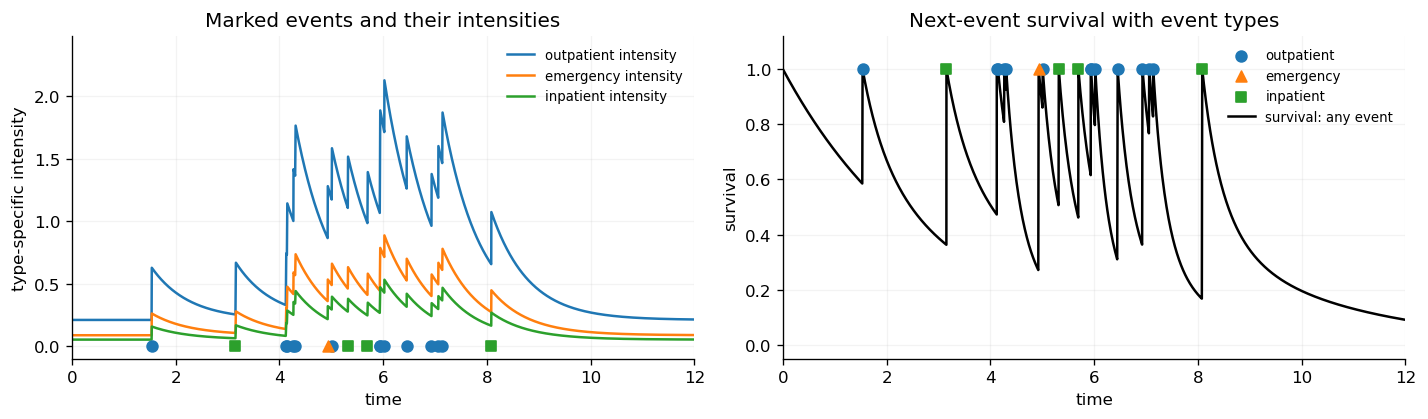

In [4]:
# Illustrative marked Hawkes process: independent marks with fixed probabilities.
# This special case shares the unmarked total intensity; it does not fit clinical data.
mark_names = ["outpatient", "emergency", "inpatient"]
mark_weights = np.array([.6, .25, .15])
mark_colours = ["tab:blue", "tab:orange", "tab:green"]
mark_symbols = ["o", "^", "s"]
mark_rng = np.random.default_rng(12)
marks = mark_rng.choice(3, size=len(hawkes_events), p=mark_weights)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for k, (name, colour, symbol) in enumerate(zip(mark_names, mark_colours, mark_symbols)):
    axes[0].plot(grid, mark_weights[k] * lam, color=colour, label=f"{name} intensity")
    selected = hawkes_events[marks == k]
    axes[0].scatter(selected, np.zeros_like(selected), color=colour, marker=symbol, s=42, zorder=3)
    axes[1].scatter(selected, np.ones_like(selected), color=colour, marker=symbol, s=42, label=name, zorder=3)
axes[0].set(xlabel="time", ylabel="type-specific intensity", ylim=(-.1, max(lam)*.7), title="Marked events and their intensities")
axes[1].plot(grid, next_wait_survival(grid, hawkes_events, mu, alpha, beta), color="black", label="survival: any event")
axes[1].set(xlabel="time", ylabel="survival", ylim=(-.05, 1.12), title="Next-event survival with event types")
for ax in axes:
    ax.set(xlim=(0, horizon))
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=.15)
fig.tight_layout()
plt.show()


## Intensity, hazard, survival and the next inter-arrival time

Suppose the latest event occurred at \(t_n\). Let \(T=t_{n+1}-t_n\) be the random **next inter-arrival time (IAT)**, and let \(\tau\geq0\) denote elapsed time since \(t_n\). Condition on the history \(\mathcal H_{t_n}\); in the formulas below we suppress this conditioning for readability. Any additional future covariates are assumed known; otherwise their future paths must also be modelled or integrated out.

The **survival function** is the probability that we are still waiting:

\[
S(\tau)=P(T>\tau),\qquad F(\tau)=1-S(\tau).
\]

Here “survival” means **no next event yet**, not necessarily that the patient is alive. The density \(f(\tau)=F'(\tau)\) describes where waiting times fall: \(f(\tau)d\tau\) approximates the probability that the next IAT lies in a short interval near \(\tau\).

The **hazard** asks a different, conditional question: given that no event has occurred yet, how quickly might one happen now?

\[
h(\tau)=\lim_{d\tau\downarrow0}
\frac{P(\tau\leq T<\tau+d\tau\mid T\geq\tau)}{d\tau}
=\frac{f(\tau)}{S(\tau)}.
\]

Both hazard and intensity have units of inverse time; neither is itself a probability. Along the history extended from \(t_n\) with **no new events**, the point-process intensity is exactly this hazard:

\[
h(\tau)=\lambda(t_n+\tau\mid\mathcal H_{t_n},\ T\geq\tau).
\]

Intensity uses the calendar-time clock \(t\); the next-IAT hazard uses the elapsed-time clock \(\tau\). For a Hawkes process, the previous events' excitation decays while we wait; a new event then updates the history and starts the next waiting-time problem.

Define the **cumulative hazard** \(A(\tau)=\int_0^\tau h(u)\,du\). Since \(S'(\tau)=-f(\tau)=-h(\tau)S(\tau)\),

\[
S(\tau)=e^{-A(\tau)},\qquad
f(\tau)=h(\tau)S(\tau),\qquad
h(\tau)=-\frac{d}{d\tau}\log S(\tau).
\]

These identities connect the same model's views: an intensity determines a waiting-time distribution, and a continuous waiting-time distribution determines a hazard wherever \(S>0\). If the cumulative hazard stays finite as \(\tau\to\infty\), there is positive probability that no further event ever occurs; an ordinary proper IAT density instead assumes the next event eventually occurs.

**Poisson example.** With \(h(\tau)=0.8\) per year, \(S(\tau)=e^{-0.8\tau}\) and \(f(\tau)=0.8e^{-0.8\tau}\). The probability of waiting more than one year is \(e^{-0.8}\approx0.449\); the probability of an event within one year is about \(0.551\). The mean IAT is \(1/0.8=1.25\) years. More generally, for a proper nonnegative IAT, \(E[T]=\int_0^\infty S(\tau)d\tau\), which may be infinite.

For a marked process, the joint density of the next IAT and its type is

\[
f_k(\tau)=S(\tau)\lambda_k(t_n+\tau\mid\mathcal H_{t_n},T\geq\tau),
\qquad f(\tau)=\sum_k f_k(\tau).
\]

The survival term uses the **total** hazard, because we are waiting for the next event of any type.

This is the route used later in the tutorials: a normalizing flow learns the conditional IAT distribution directly. Its density and survival function provide both event likelihoods and censoring terms; the corresponding hazard is \(f/S\).


### One waiting-time distribution, five linked views

The plots below fix the current history and look forward with **no further events yet**. Blue shows a Poisson rate of 0.8 per year. Orange shows a Hawkes model immediately after one event at time zero, with empty earlier history: \(h(\tau)=0.35+0.7e^{-1.4\tau}\). Thus the Hawkes intensity along this no-event continuation is the orange hazard curve. These are conditional next-event distributions, not simulated event timelines, so the curves do not restart.

Read left to right: integrate hazard to get cumulative hazard; exponentiate its negative to get survival; multiply hazard by survival to get density; subtract survival from one to get the CDF. The blue shaded area under hazard up to one year is \(A(1)\). The blue shaded area under density from one to 1.25 years is the **unconditional-on-waiting** probability \(P(1<T\leq1.25)\), still conditional on the fixed starting history. Divide that probability by \(S(1)\) to condition further on having already waited one year. The final panel gives the numbers.


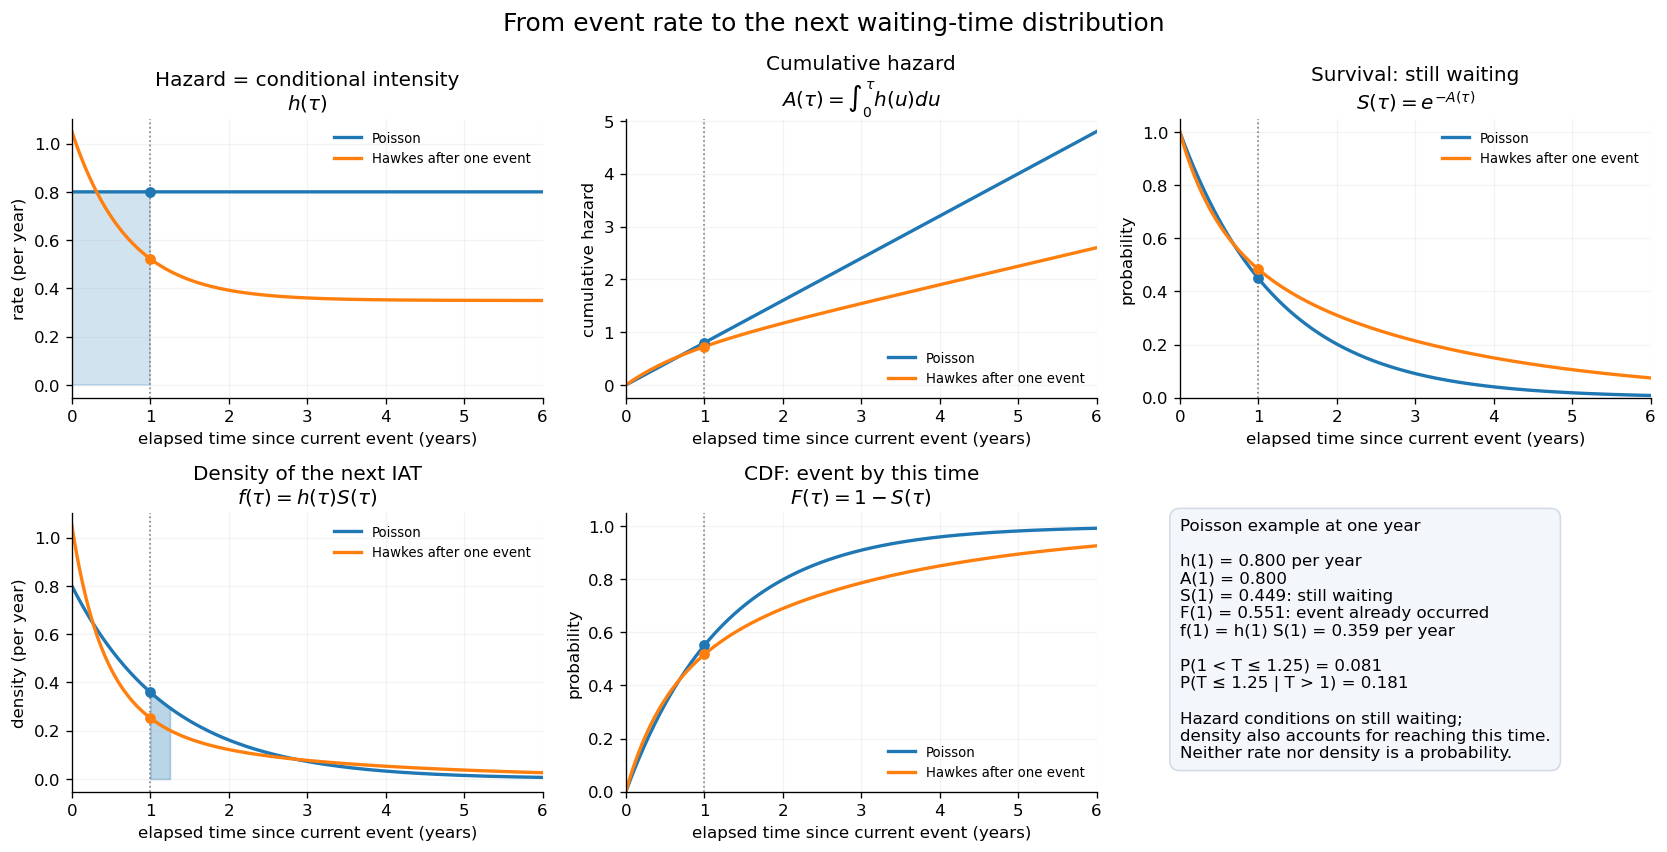

In [5]:
tau = np.linspace(0, 6, 1201)
poisson_h = np.full_like(tau, .8)
poisson_A = .8 * tau
hawkes_h = .35 + .7 * np.exp(-1.4 * tau)
hawkes_A = .35 * tau + (.7 / 1.4) * (-np.expm1(-1.4 * tau))

fig, axes = plt.subplots(2, 3, figsize=(14, 7.2), sharex=False)
views = [
    ("Hazard = conditional intensity", "rate (per year)", r"$h(\tau)$"),
    ("Cumulative hazard", "cumulative hazard", r"$A(\tau)=\int_0^\tau h(u)du$"),
    ("Survival: still waiting", "probability", r"$S(\tau)=e^{-A(\tau)}$"),
    ("Density of the next IAT", "density (per year)", r"$f(\tau)=h(\tau)S(\tau)$"),
    ("CDF: event by this time", "probability", r"$F(\tau)=1-S(\tau)$"),
]
for label, colour, hazard, cumulative in [
    ("Poisson", "tab:blue", poisson_h, poisson_A),
    ("Hawkes after one event", "tab:orange", hawkes_h, hawkes_A),
]:
    survival = np.exp(-cumulative)
    values = [hazard, cumulative, survival, hazard * survival, 1 - survival]
    for ax, value in zip(axes.flat, values):
        ax.plot(tau, value, color=colour, label=label, linewidth=2)
        ax.scatter([1.0], [np.interp(1.0, tau, value)], color=colour, s=30, zorder=3)
for ax, (title, ylabel, formula) in zip(axes.flat, views):
    ax.set(title=title + "\n" + formula, xlabel="elapsed time since current event (years)", ylabel=ylabel, xlim=(0, 6))
    ax.axvline(1, color="grey", linestyle=":", linewidth=1)
    ax.grid(alpha=.15)
    ax.legend(frameon=False, fontsize=8)
axes[0, 2].set(ylim=(0, 1.05))
axes[1, 1].set(ylim=(0, 1.05))
axes[0, 0].fill_between(tau, 0, poisson_h, where=tau <= 1, color="tab:blue", alpha=.2)
axes[1, 0].fill_between(tau, 0, poisson_h * np.exp(-poisson_A), where=(tau >= 1) & (tau <= 1.25), color="tab:blue", alpha=.3)

S_one = np.exp(-.8)
interval_probability = S_one - np.exp(-.8 * 1.25)
conditional_probability = interval_probability / S_one
axes[1, 2].axis("off")
axes[1, 2].text(0, .98,
    "Poisson example at one year\n\n"
    f"h(1) = 0.800 per year\n"
    f"A(1) = 0.800\n"
    f"S(1) = {S_one:.3f}: still waiting\n"
    f"F(1) = {1-S_one:.3f}: event already occurred\n"
    f"f(1) = h(1) S(1) = {.8*S_one:.3f} per year\n\n"
    f"P(1 < T ≤ 1.25) = {interval_probability:.3f}\n"
    f"P(T ≤ 1.25 | T > 1) = {conditional_probability:.3f}\n\n"
    "Hazard conditions on still waiting;\ndensity also accounts for reaching this time.\n"
    "Neither rate nor density is a probability.",
    transform=axes[1, 2].transAxes, va="top", fontsize=10,
    bbox=dict(boxstyle="round,pad=.6", facecolor="#f3f6fa", edgecolor="#d4dce6"))
fig.suptitle("From event rate to the next waiting-time distribution", fontsize=15)
fig.tight_layout()
plt.show()


## From one patient to a patient database (concept only)

Per-patient fitting estimates a separate Poisson rate or Hawkes parameter set for each patient's own observation window and history. Fitting a shared model across a database instead maximises the **sum of patient log-likelihoods**:

\[
\ell(\theta)=\sum_{p=1}^{P}\left[
\sum_i\log\lambda_\theta(t_{pi}\mid\mathcal H_{p,t_{pi}})
-\int_{a_p}^{C_p}\lambda_\theta(s\mid\mathcal H_{p,s})\,ds\right].
\]

Each patient retains their own entry time \(a_p\), endpoint \(C_p\) and event history. Do not concatenate patients into one Hawkes timeline: an event in one patient must not excite another patient's intensity. Include zero-event patients and each censored tail.

For a homogeneous Poisson model with one shared rate, the estimate is total events divided by total patient exposure, \(\widehat\lambda=\sum_p N_p/\sum_p(C_p-a_p)\). For shared Hawkes parameters, jointly optimise the summed likelihood with the same parameter constraints and a separate history for every patient. A hierarchical model or covariate-conditioned parameters can share information while allowing patients to differ. Validate with held-out patients when assessing generalisation to new patients. Database fitting is described here only; no fitting implementation is added.


## Why clinical timelines are harder than the textbook example

| Clinical property | What it means for a TPP |
|---|---|
| Right censoring | The last interval is not an event; it contributes a survival term \(\log S(C-t_N)\). |
| Unknown pre-study history | No events before cohort entry are **not observed**, not absent. A vanilla TPP started at birth would be misspecified. |
| Irregular measurements | Measurements can be events/marks themselves, or time-varying covariates; their observation process may be informative. |
| Dynamic physiology | \(\lambda(t)\) should depend on a causal state summarising measurements and prior events. |
| Multiple event types | Use a marked TPP: jointly model when something happens and what type of event it is. |
| Long dependencies | Simple Hawkes kernels may be too rigid; an encoder such as a Transformer can summarise a long history. |

**Where TPPs excel:** modelling event timing, censoring, recurrent events and full distributions of the next event time.

**Where they are not naturally strongest:** reconstructing a smooth continuous physiological trajectory between sparse measurements. That is the role for Gaussian processes in the next notebook.

### What right censoring means

**Right censoring** occurs when observation ends before the next event is seen. We know a lower bound on the next waiting time, but not its eventual value. The end of follow-up is an observation boundary, not an event.

For example, suppose a patient's last visit occurs at year 8 and follow-up ends at year 10. We observed two years without another visit, so the next IAT satisfies \(T>2\) years. It would be incorrect to record an event at year 10 or train the model as if the next IAT were exactly two years. The patient might have another visit later; the dataset does not reveal when.

For an observed next event after \(\tau\), the likelihood contribution is \(f(\tau\mid\mathcal H)\). For a right-censored wait of length \(c=C-t_N\), it is instead

\[
P(T>c\mid\mathcal H)=S(c\mid\mathcal H),
\qquad
\log S(c\mid\mathcal H)=-\int_0^c h(u\mid\mathcal H)\,du.
\]

For the Poisson example with rate \(0.8\) per year, a two-year censored tail contributes \(S(2)=e^{-1.6}\approx0.202\), or \(\log S(2)=-1.6\). This penalises a model that predicts many events during a period in which none were observed. It supplies useful information even though the next event time is unknown.

The full point-process likelihood combines densities for completed waiting times with survival for the final incomplete interval. Its integral through \(C\), shown at the start of this notebook, already includes this censored tail; do not add the same survival term twice. If there are no observed events, the whole observation window contributes a no-event survival probability conditional on the entry history.

This treatment assumes that the observation endpoint is fixed or censoring is non-informative conditional on the modelled information. If patients stop being observed because of an unmodelled worsening condition, their dropout may need a joint model. Death, when observed and relevant, should be represented explicitly as a terminal event rather than silently treated as ordinary loss of follow-up.


## A patient timeline from the supplied dataset

The textbook examples above simulate simple processes. Here we load **one patient from `data/synthetic/`**, using its recorded event times and measurements. This is a concrete dataset example, not a real person's medical record: the repository's cohort is synthetic.

We select a patient with all three visit types, hidden pre-study events, independently scheduled measurements and a long event-free tail so the distinctions are visible. This illustrative selection is not intended to be representative of the cohort.

- **Grey crosses before entry:** simulated pre-study visits, visible only as oracle truth. They must not be passed to a model as observed history. Their absence from the observed record does not mean there were no earlier visits.
- **Blue background and dashed boundaries:** the observation window, from cohort entry to the end of follow-up. The end boundary is not a visit or a death event.
- **Coloured visit symbols:** outpatient, emergency and inpatient marks use different colours and shapes.
- **Orange interval after the final visit:** right-censored time with no observed visit. The next visit's waiting time is only known to exceed this interval; it contributes a survival likelihood. Measurements or covariate updates can still occur in this interval.
- **Separate physiological panels:** the actual measured values occur at irregular ages. Circles indicate event-linked panels; diamonds indicate independently scheduled panels. There are no interpolated values or filled gaps.
- **Covariate row:** times of recorded updates to EHR history, employment or marital status, which need not coincide with visits. It displays update times, not the covariate values themselves.


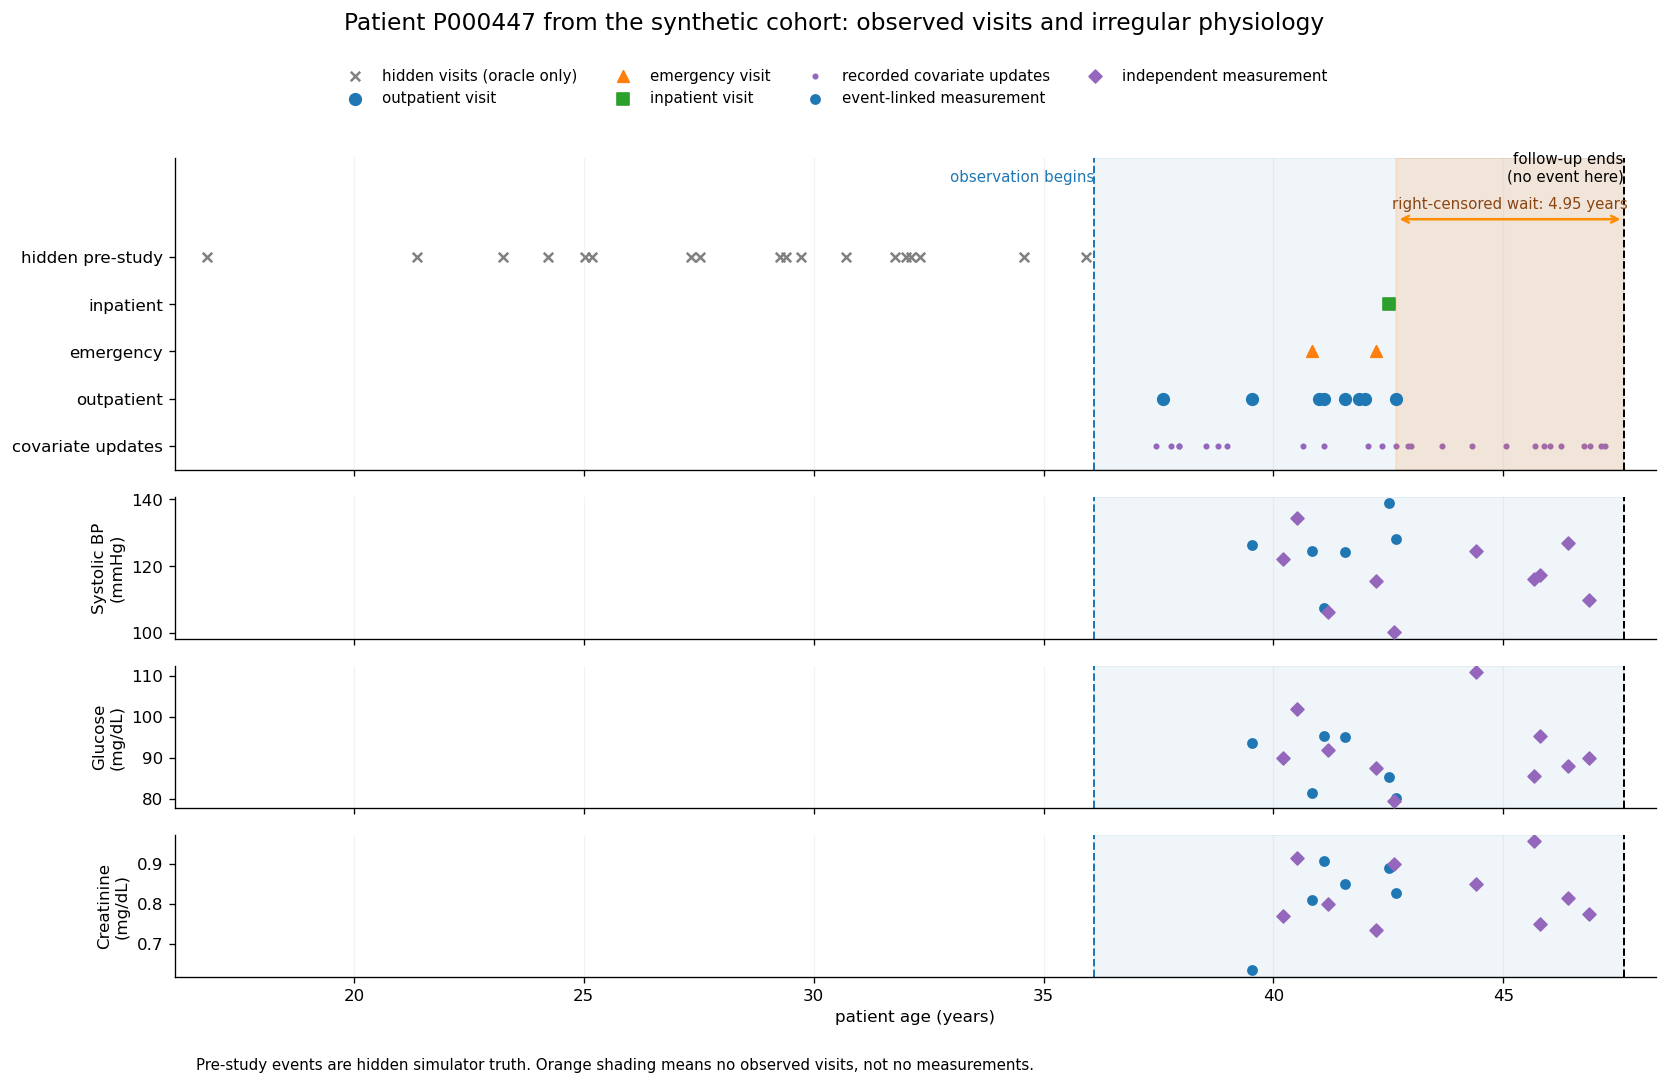

P000447: 11 observed visits, 18 hidden pre-study visits; entry age 36.10, end age 47.62.
Right-censored wait after the last visit: 1809.0 days (4.95 years).
Measurement timestamps: 16; recorded covariate updates: 25.


In [6]:
from lifetime_clinical.data import load_dataset
from lifetime_clinical.visualization import plot_patient_clinical_timeline

clinical = load_dataset(ROOT / "data" / "synthetic")
# Select once from recorded table properties, then break ties deterministically.
candidates = clinical.patients.copy()
candidates["hidden_count"] = candidates.patient_id.map(clinical.pre_study_events.groupby("patient_id").size()).fillna(0)
candidates["visit_types"] = candidates.patient_id.map(clinical.events.groupby("patient_id").event_type.nunique()).fillna(0)
independent = clinical.measurements[clinical.measurements.measurement_source == "independent"]
candidates["independent_count"] = candidates.patient_id.map(independent.groupby("patient_id").size()).fillna(0)
candidates = candidates[
    (candidates.hidden_count > 0) & (candidates.visit_types == 3)
    & (candidates.independent_count > 0)
    & candidates.n_observed_events.between(8, 20)
    & (candidates.right_censor_days > 180)
].sort_values(["right_censor_days", "patient_id"], ascending=[False, True])
if candidates.empty:
    raise ValueError("No patient satisfies the illustrative timeline selection criteria")
patient = candidates.iloc[0]
pid = patient.patient_id
visits = clinical.events[clinical.events.patient_id == pid].sort_values("event_age")
hidden = clinical.pre_study_events[clinical.pre_study_events.patient_id == pid]
measured = clinical.measurements[clinical.measurements.patient_id == pid]
updates = clinical.dynamic_covariates[
    (clinical.dynamic_covariates.patient_id == pid)
    & (clinical.dynamic_covariates.source == "update")
]
entry, endpoint = float(patient.start_study_age), float(patient.censor_age)
last_visit = float(visits.event_age.max())
tail_years = endpoint - last_visit
fig, axes = plot_patient_clinical_timeline(
    clinical, pid, show_hidden=True,
    title=f"Patient {pid} from the synthetic cohort: observed visits and irregular physiology",
)
plt.show()
print(f"{pid}: {len(visits)} observed visits, {len(hidden)} hidden pre-study visits; entry age {entry:.2f}, end age {endpoint:.2f}.")
print(f"Right-censored wait after the last visit: {patient.right_censor_days:.1f} days ({tail_years:.2f} years).")
print(f"Measurement timestamps: {measured.measurement_date.nunique()}; recorded covariate updates: {len(updates)}.")
